<a href="https://colab.research.google.com/github/dewianggrainimeita/PCVK_Ganjil_2026/blob/main/Pertemuan%207/Week07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
NAMA = 'Dewi Anggraini Meita Sari'
NIM  = '244107020068'
print('NAMA :', NAMA)
print('NIM  :', NIM)

NAMA : Dewi Anggraini Meita Sari
NIM  : 244107020068


In [2]:
from google.colab import drive

# Menghubungkan Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


# Global Threshold

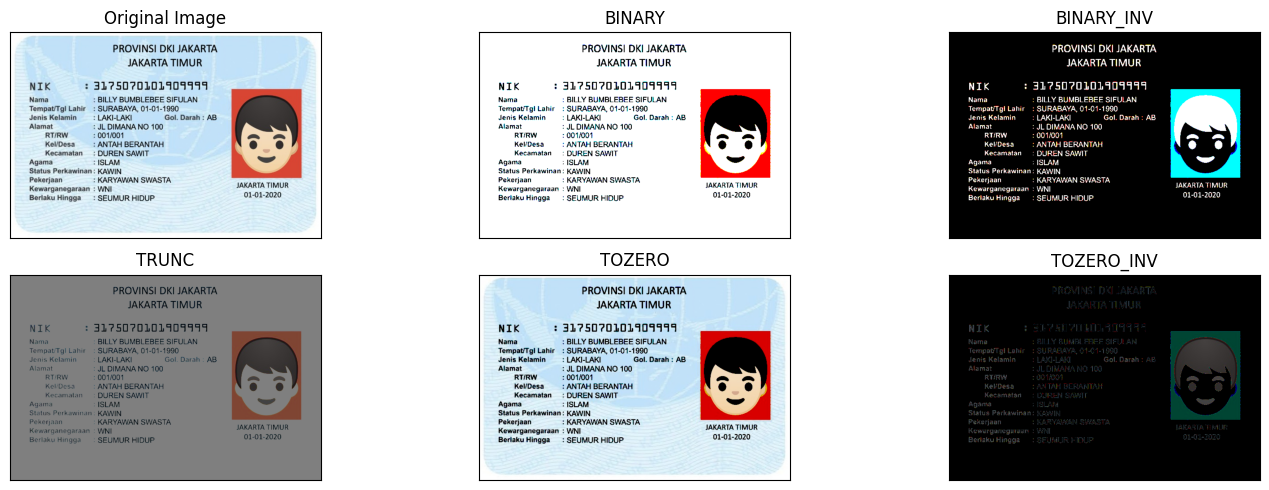

In [3]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt

# Membaca gambar
filename = '/content/drive/MyDrive/Semester 5/PCVK/image/ktpEx.jpeg'
img = cv.imread(filename)

# Memeriksa apakah gambar berhasil dibaca
if img is None:
    print("Gambar tidak ditemukan. Periksa kembali lokasi file.")
else:
    thresh = 127  # Nilai threshold yang ditentukan
    maxval = 255

    # 1. Threshold Binary
    ret, thresh1 = cv.threshold(img, thresh, maxval, cv.THRESH_BINARY)

    # 2. Threshold Binary Inverse
    ret, thresh2 = cv.threshold(img, thresh, maxval, cv.THRESH_BINARY_INV)

    # 3. Threshold Truncate
    ret, thresh3 = cv.threshold(img, thresh, maxval, cv.THRESH_TRUNC)

    # 4. Threshold Tozero
    ret, thresh4 = cv.threshold(img, thresh, maxval, cv.THRESH_TOZERO)

    # 5. Threshold Tozero Inverse
    ret, thresh5 = cv.threshold(img, thresh, maxval, cv.THRESH_TOZERO_INV)

    # Judul dan daftar gambar
    titles = [
        'Original Image',
        'BINARY',
        'BINARY_INV',
        'TRUNC',
        'TOZERO',
        'TOZERO_INV'
    ]

    images = [
        img,
        thresh1,
        thresh2,
        thresh3,
        thresh4,
        thresh5
    ]

    # Menampilkan seluruh gambar
    plt.figure(figsize=(15, 5))

    for i in range(len(images)):
        plt.subplot(2, 3, i + 1)

        # OpenCV membaca gambar dalam format BGR,
        # sehingga perlu dikonversi ke RGB untuk Matplotlib.
        if len(images[i].shape) == 3:
            display_img = cv.cvtColor(images[i], cv.COLOR_BGR2RGB)
            plt.imshow(display_img)
        else:
            plt.imshow(images[i], cmap='gray', interpolation='nearest')

        plt.title(titles[i])
        plt.xticks([])
        plt.yticks([])

    plt.tight_layout()
    plt.show()


# Adaptive Threshold

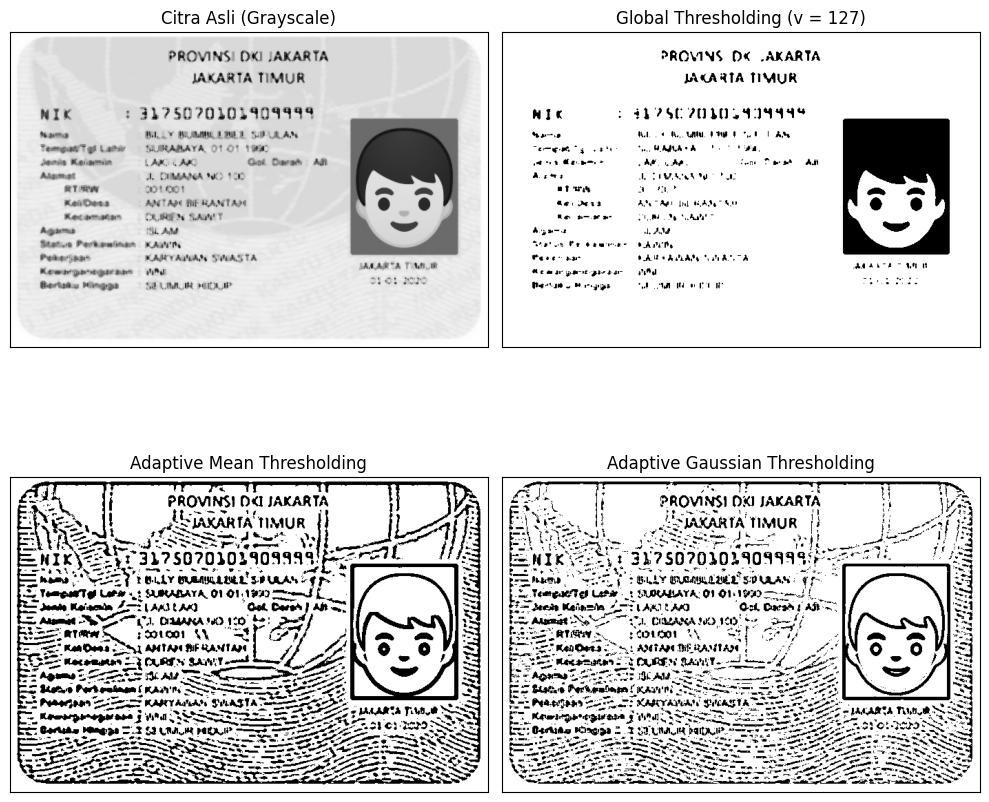

In [4]:

import cv2 as cv
import matplotlib.pyplot as plt

# Membaca citra dari Google Drive
filename = '/content/drive/MyDrive/Semester 5/PCVK/image/ktpEx.jpeg'
img = cv.imread(filename)

# Memeriksa apakah gambar berhasil dibaca
if img is None:
    print("Gambar tidak ditemukan. Periksa kembali lokasi file.")
else:
    # Mengurangi noise menggunakan Median Blur
    citra = cv.medianBlur(img, 5)

    # Mengubah citra menjadi grayscale
    gray = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)

    # 1. Global Thresholding
    thresh = 127
    ret, th1 = cv.threshold(
        gray, thresh, 255, cv.THRESH_BINARY
    )

    # 2. Adaptive Mean Thresholding
    th2 = cv.adaptiveThreshold(
        gray,
        255,
        cv.ADAPTIVE_THRESH_MEAN_C,
        cv.THRESH_BINARY,
        11,
        2
    )

    # 3. Adaptive Gaussian Thresholding
    th3 = cv.adaptiveThreshold(
        gray,
        255,
        cv.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv.THRESH_BINARY,
        11,
        2
    )

    # Judul dan daftar citra
    titles = [
        'Citra Asli (Grayscale)',
        'Global Thresholding (v = 127)',
        'Adaptive Mean Thresholding',
        'Adaptive Gaussian Thresholding'
    ]

    citra2 = [gray, th1, th2, th3]

    # Menampilkan hasil
    plt.figure(figsize=(10, 10))

    for i in range(len(citra2)):
        plt.subplot(2, 2, i + 1)
        plt.imshow(citra2[i], cmap='gray')
        plt.title(titles[i])
        plt.xticks([])
        plt.yticks([])

    plt.tight_layout()
    plt.show()

# Otsu’s Threshold

/tmp/ipykernel_1422/4147563234.py:41: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(blur.ravel(), 256, [0, 256])


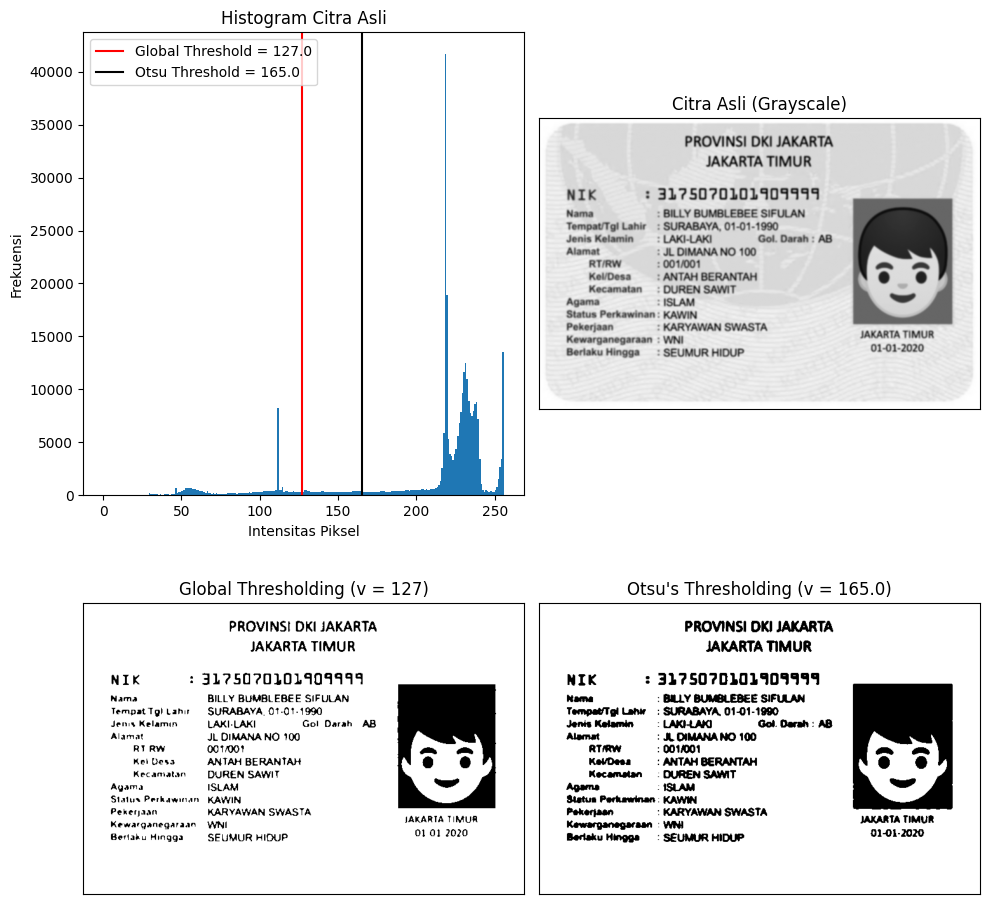

In [5]:

import cv2 as cv
import matplotlib.pyplot as plt

# Membaca citra dalam format grayscale
filename = '/content/drive/MyDrive/Semester 5/PCVK/image/ktpEx.jpeg'
img = cv.imread(filename, 0)

# Memeriksa apakah gambar berhasil dibaca
if img is None:
    print("Gambar tidak ditemukan. Periksa kembali lokasi file.")
else:
    # Mengurangi noise menggunakan Gaussian Blur
    blur = cv.GaussianBlur(img, (5, 5), 0)

    # Global Thresholding dengan nilai 127
    thresh = 127
    ret, th1 = cv.threshold(
        blur, thresh, 255, cv.THRESH_BINARY
    )

    # Otsu's Thresholding
    ret2, th2 = cv.threshold(
        blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU
    )

    # Judul gambar
    x = "Otsu's Thresholding (v = " + str(ret2) + ")"
    titles = [
        'Citra Asli (Grayscale)',
        'Global Thresholding (v = 127)',
        x
    ]

    citra3 = [blur, th1, th2]

    # Membuat visualisasi
    plt.figure(figsize=(10, 10))

    # Histogram citra
    plt.subplot(2, 2, 1)
    plt.hist(blur.ravel(), 256, [0, 256])
    plt.axvline(
        ret, color='red',
        label=f'Global Threshold = {ret}'
    )
    plt.axvline(
        ret2, color='black',
        label=f'Otsu Threshold = {ret2}'
    )
    plt.title('Histogram Citra Asli')
    plt.xlabel('Intensitas Piksel')
    plt.ylabel('Frekuensi')
    plt.legend()

    # Menampilkan citra dan hasil thresholding
    for i in range(len(citra3)):
        plt.subplot(2, 2, i + 2)
        plt.imshow(citra3[i], cmap='gray')
        plt.title(titles[i])
        plt.xticks([])
        plt.yticks([])

    plt.tight_layout()
    plt.show()

# threshold Otsu’s tanpa Gaussian Filter dan dengan menggunakan Gaussian Filter.

/tmp/ipykernel_1422/3059860216.py:57: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(images[i * 2].ravel(), 256, [0, 256])


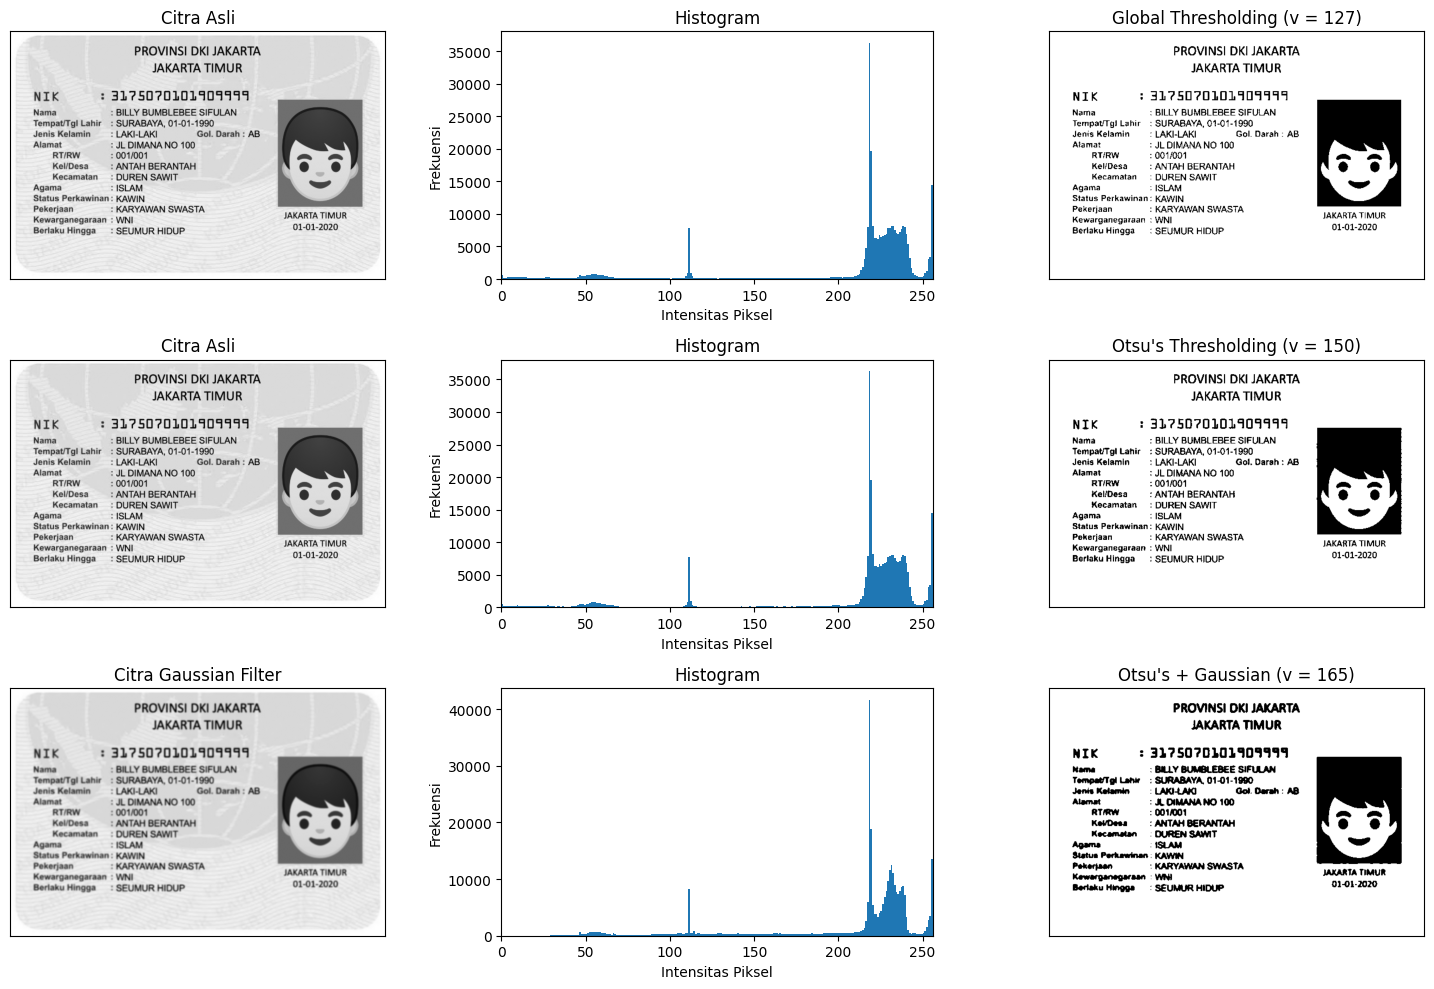

In [6]:

import cv2 as cv
import matplotlib.pyplot as plt

# Membaca citra dalam format grayscale
filename = '/content/drive/MyDrive/Semester 5/PCVK/image/ktpEx.jpeg'
img = cv.imread(filename, 0)

# Memeriksa apakah gambar berhasil dibaca
if img is None:
    print("Gambar tidak ditemukan. Periksa kembali lokasi file.")
else:
    # 1. Global Thresholding
    ret1, th1 = cv.threshold(
        img, 127, 255, cv.THRESH_BINARY
    )

    # 2. Otsu's Thresholding
    ret2, th2 = cv.threshold(
        img, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU
    )

    # 3. Otsu's Thresholding setelah Gaussian Filtering
    blur = cv.GaussianBlur(img, (5, 5), 0)
    ret3, th3 = cv.threshold(
        blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU
    )

    # Data gambar dan judul
    images = [
        img, th1,
        img, th2,
        blur, th3
    ]

    titles = [
        'Citra Asli',
        'Global Thresholding (v = 127)',
        'Citra Asli',
        f"Otsu's Thresholding (v = {ret2:.0f})",
        'Citra Gaussian Filter',
        f"Otsu's + Gaussian (v = {ret3:.0f})"
    ]

    # Menampilkan hasil dalam 3 baris dan 3 kolom
    plt.figure(figsize=(15, 10))

    for i in range(3):
        # Kolom 1: Citra input
        plt.subplot(3, 3, i * 3 + 1)
        plt.imshow(images[i * 2], cmap='gray')
        plt.title(titles[i * 2])
        plt.xticks([])
        plt.yticks([])

        # Kolom 2: Histogram citra input
        plt.subplot(3, 3, i * 3 + 2)
        plt.hist(images[i * 2].ravel(), 256, [0, 256])
        plt.title('Histogram')
        plt.xlabel('Intensitas Piksel')
        plt.ylabel('Frekuensi')
        plt.xlim([0, 256])

        # Kolom 3: Hasil thresholding
        plt.subplot(3, 3, i * 3 + 3)
        plt.imshow(images[i * 2 + 1], cmap='gray')
        plt.title(titles[i * 2 + 1])
        plt.xticks([])
        plt.yticks([])

    plt.tight_layout()
    plt.show()

#  K-Means pada segmentasi citra

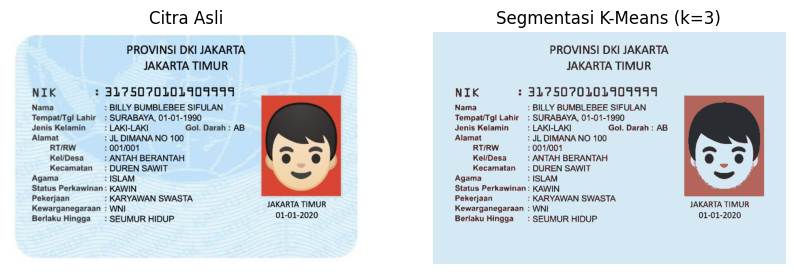

In [7]:
import cv2
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
# Baca citra dan ubah ke RGB
filename = ('/content/drive/MyDrive/Semester 5/PCVK/image/ktpEx.jpeg')
img = cv.imread(filename)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
# Ubah citra menjadi array 2D (piksel)
Z = img.reshape((-1, 3))
Z = np.float32(Z)
# Tentukan jumlah cluster
k = 3
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(Z)
# Dapatkan label dan pusat cluster
labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)
# Bentuk citra hasil segmentasi
segmented = centers[labels.flatten()]
segmented_img = segmented.reshape(img.shape)
# Tampilkan hasil
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Citra Asli')
plt.axis('off')
plt.subplot(1,2,2)
plt.imshow(segmented_img)
plt.title('Segmentasi K-Means (k=3)')
plt.axis('off')
plt.show()

#== Tugas Praktikum ==

In [8]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

# No 1

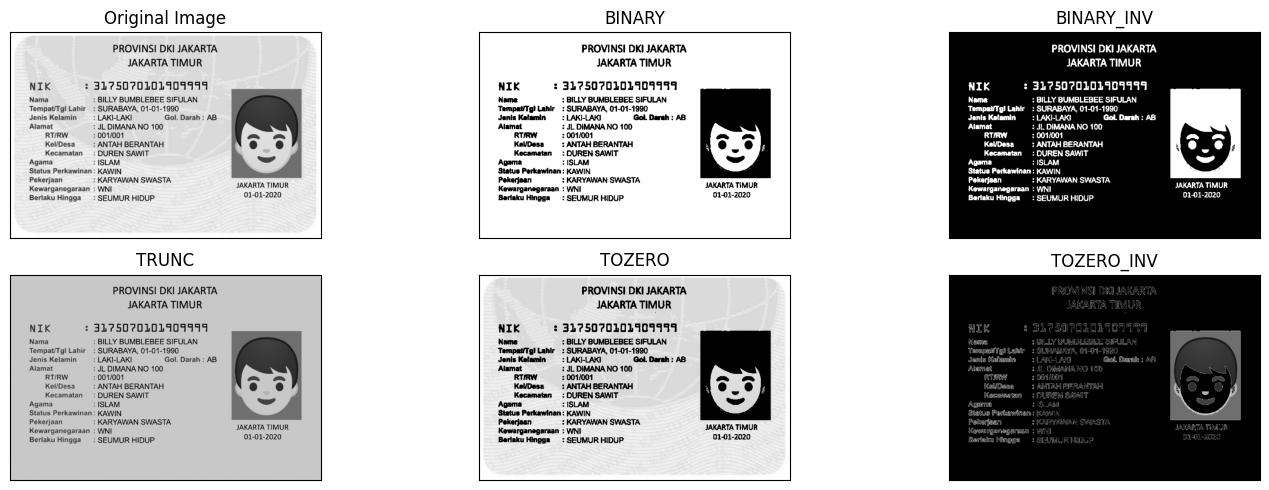

In [9]:

import cv2 as cv
import matplotlib.pyplot as plt

# Membaca citra grayscale
filename = '/content/drive/MyDrive/Semester 5/PCVK/image/ktpEx.jpeg'
img = cv.imread(filename, 0)

if img is None:
    print("Gambar tidak ditemukan. Periksa lokasi file.")
else:
    # Threshold yang ditentukan secara manual
    thresh = 200
    maxval = 255

    # 1. Binary
    ret, thresh1 = cv.threshold(
        img, thresh, maxval, cv.THRESH_BINARY
    )

    # 2. Binary Inverse
    ret, thresh2 = cv.threshold(
        img, thresh, maxval, cv.THRESH_BINARY_INV
    )

    # 3. Truncate
    ret, thresh3 = cv.threshold(
        img, thresh, maxval, cv.THRESH_TRUNC
    )

    # 4. Tozero
    ret, thresh4 = cv.threshold(
        img, thresh, maxval, cv.THRESH_TOZERO
    )

    # 5. Tozero Inverse
    ret, thresh5 = cv.threshold(
        img, thresh, maxval, cv.THRESH_TOZERO_INV
    )

    # Judul dan hasil citra
    titles = [
        'Original Image',
        'BINARY',
        'BINARY_INV',
        'TRUNC',
        'TOZERO',
        'TOZERO_INV'
    ]

    images = [
        img, thresh1, thresh2,
        thresh3, thresh4, thresh5
    ]

    # Menampilkan hasil thresholding
    plt.figure(figsize=(15, 5))

    for i in range(len(images)):
        plt.subplot(2, 3, i + 1)
        plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
        plt.title(titles[i])
        plt.xticks([])
        plt.yticks([])

    plt.tight_layout()
    plt.show()


# No 2

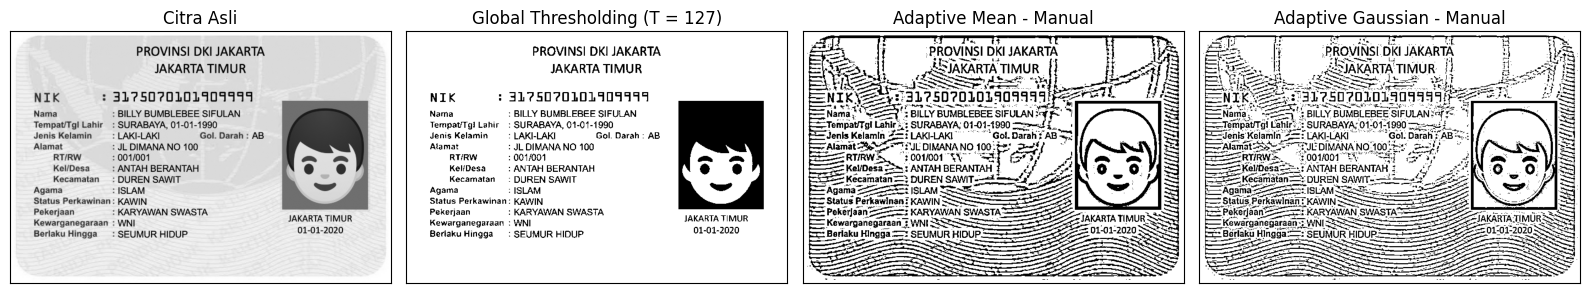

In [10]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Membaca citra Sudoku dalam grayscale
filename = '/content/drive/MyDrive/Semester 5/PCVK/image/ktpEx.jpeg'
img = cv.imread(filename, 0)

if img is None:
    print("Gambar tidak ditemukan. Periksa lokasi file.")
else:
    # Parameter
    T = 127
    block_size = 11
    C = 2
    sigma = 2

    # 1. Global Thresholding manual
    global_thresh = np.where(img > T, 255, 0).astype(np.uint8)

    # Padding agar jendela dapat diproses sampai tepi gambar
    pad = block_size // 2
    padded = np.pad(img, pad, mode='reflect')

    height, width = img.shape

    # Menyiapkan hasil Adaptive Mean dan Gaussian
    adaptive_mean = np.zeros((height, width), dtype=np.uint8)
    adaptive_gaussian = np.zeros((height, width), dtype=np.uint8)

    # Membuat kernel Gaussian secara manual
    ax = np.arange(-pad, pad + 1)
    xx, yy = np.meshgrid(ax, ax)

    gaussian_kernel = np.exp(
        -(xx**2 + yy**2) / (2 * sigma**2)
    )
    gaussian_kernel /= gaussian_kernel.sum()

    # 2. Adaptive Thresholding secara manual
    for y in range(height):
        for x in range(width):
            # Mengambil jendela 11 x 11
            window = padded[y:y + block_size, x:x + block_size]

            # Adaptive Mean: rata-rata lokal
            mean_value = np.mean(window)
            threshold_mean = mean_value - C

            # Adaptive Gaussian: rata-rata berbobot Gaussian
            gaussian_value = np.sum(window * gaussian_kernel)
            threshold_gaussian = gaussian_value - C

            # Membandingkan piksel dengan threshold lokal
            adaptive_mean[y, x] = (
                255 if img[y, x] > threshold_mean else 0
            )

            adaptive_gaussian[y, x] = (
                255 if img[y, x] > threshold_gaussian else 0
            )

    # 3. Menampilkan hasil
    titles = [
        'Citra Asli',
        'Global Thresholding (T = 127)',
        'Adaptive Mean - Manual',
        'Adaptive Gaussian - Manual'
    ]

    images = [
        img,
        global_thresh,
        adaptive_mean,
        adaptive_gaussian
    ]

    plt.figure(figsize=(16, 5))

    for i in range(len(images)):
        plt.subplot(1, 4, i + 1)
        plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
        plt.title(titles[i])
        plt.xticks([])
        plt.yticks([])

    plt.tight_layout()
    plt.show()


# No 3

Global Threshold = 127
Otsu Threshold = 124


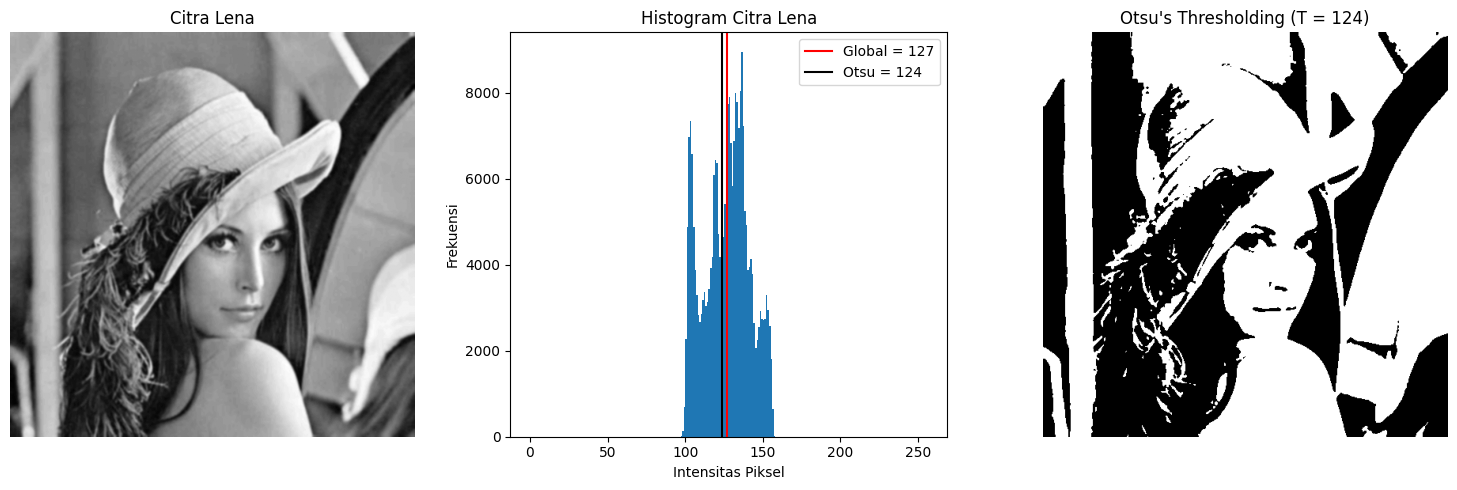

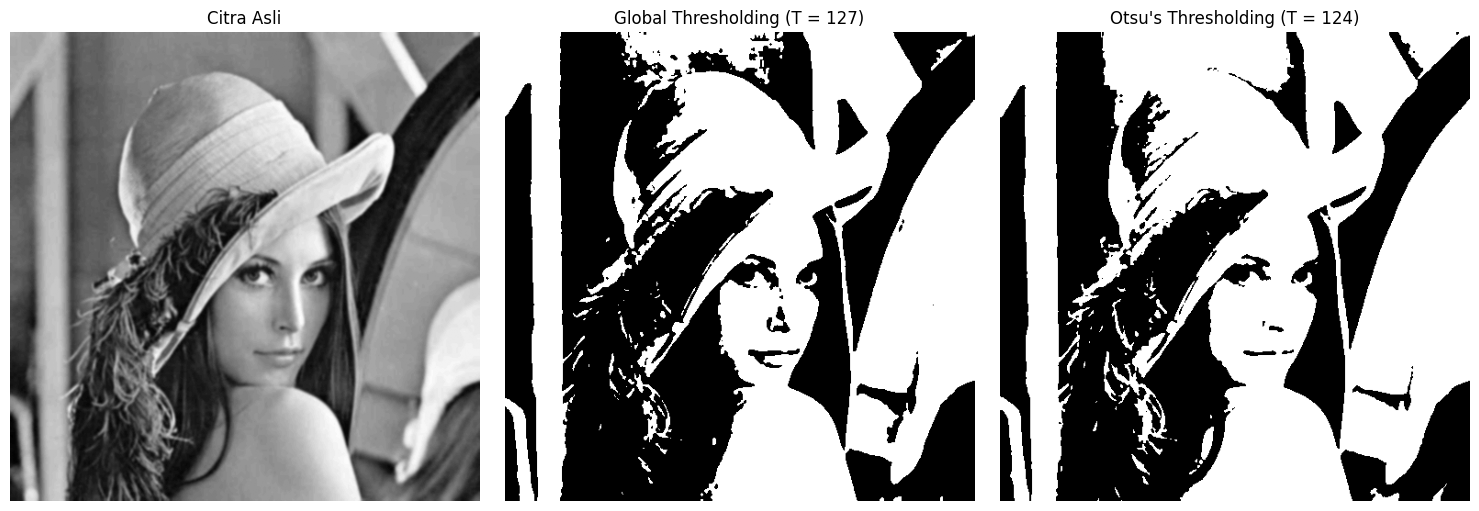

In [11]:

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Membaca gambar Lena dalam grayscale
filename = '/content/drive/MyDrive/Semester 5/PCVK/image/lena_lc.jpeg'
img = cv.imread(filename, 0)

if img is None:
    print("Gambar Lena tidak ditemukan. Periksa lokasi file.")
else:
    # Gaussian Blur
    blur = cv.GaussianBlur(img, (5, 5), 0)

    # Global Thresholding manual
    thresh = 127
    global_thresh = np.where(blur > thresh, 255, 0).astype(np.uint8)

    # Fungsi Otsu manual
    def otsu(gray):
        # Histogram intensitas piksel 0-255
        hist = np.bincount(gray.ravel(), minlength=256).astype(np.float64)

        total = gray.size
        total_sum = np.sum(np.arange(256) * hist)

        weight_background = 0
        sum_background = 0
        max_variance = -1
        best_thresh = 0

        for t in range(256):
            weight_background += hist[t]
            sum_background += t * hist[t]

            weight_foreground = total - weight_background

            if weight_background == 0 or weight_foreground == 0:
                continue

            mean_background = sum_background / weight_background
            mean_foreground = (
                total_sum - sum_background
            ) / weight_foreground

            # Varians antarkelas
            variance = (
                weight_background
                * weight_foreground
                * (mean_background - mean_foreground) ** 2
            )

            if variance > max_variance:
                max_variance = variance
                best_thresh = t

        # Membentuk citra biner secara manual
        binary = np.where(gray > best_thresh, 255, 0).astype(np.uint8)

        return binary, best_thresh

    otsu_result, otsu_thresh = otsu(blur)

    print("Global Threshold =", thresh)
    print("Otsu Threshold =", otsu_thresh)

    # Menampilkan histogram
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(blur, cmap='gray')
    plt.title('Citra Lena')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.hist(blur.ravel(), bins=256, range=(0, 256))
    plt.axvline(thresh, color='red', label=f'Global = {thresh}')
    plt.axvline(otsu_thresh, color='black',
                label=f'Otsu = {otsu_thresh}')
    plt.title('Histogram Citra Lena')
    plt.xlabel('Intensitas Piksel')
    plt.ylabel('Frekuensi')
    plt.legend()

    plt.subplot(1, 3, 3)
    plt.imshow(otsu_result, cmap='gray')
    plt.title(f"Otsu's Thresholding (T = {otsu_thresh})")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

    # Membandingkan hasil Global dan Otsu
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(blur, cmap='gray')
    plt.title('Citra Asli')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(global_thresh, cmap='gray')
    plt.title('Global Thresholding (T = 127)')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(otsu_result, cmap='gray')
    plt.title(f"Otsu's Thresholding (T = {otsu_thresh})")
    plt.axis('off')

    plt.tight_layout()
    plt.show()


Global Threshold KTP = 127
Otsu Threshold KTP = 165


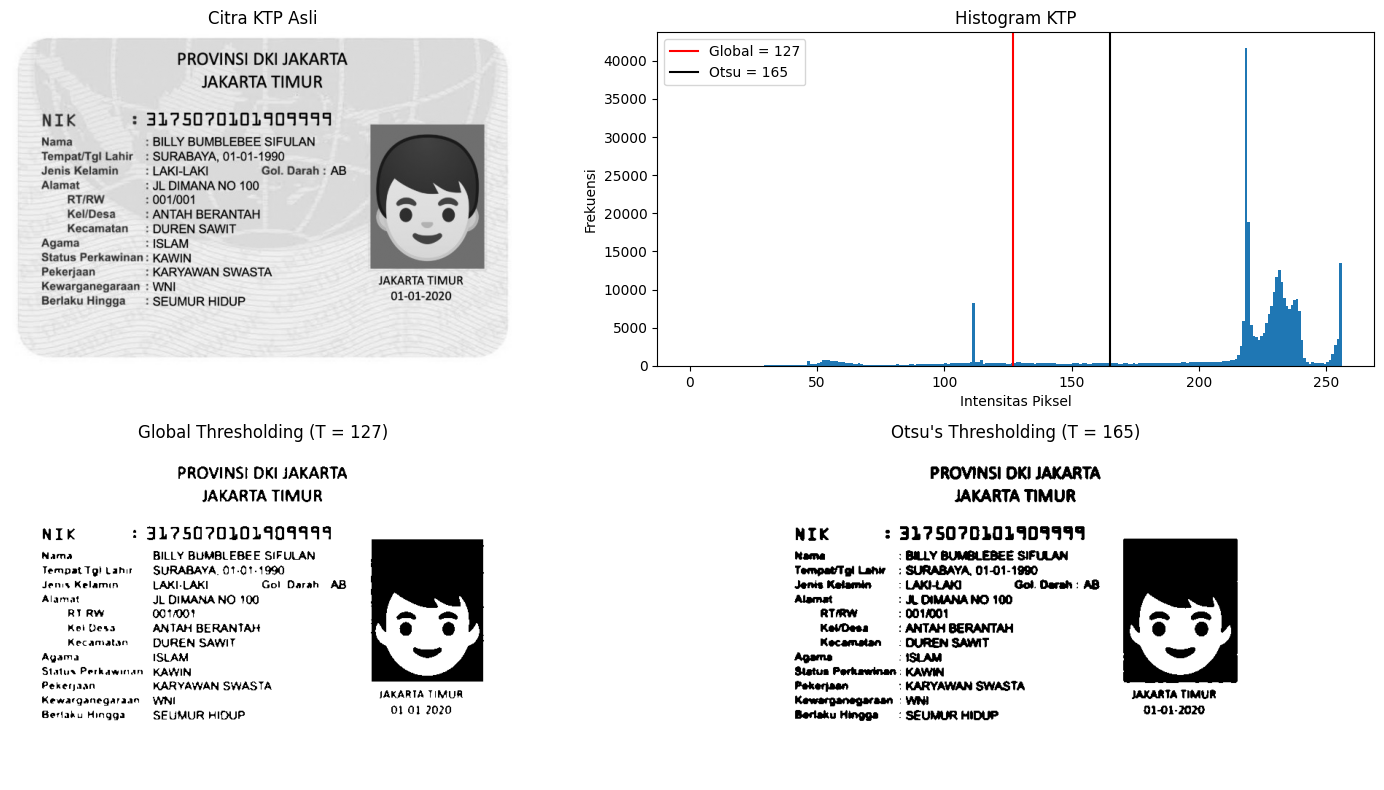

In [12]:

# Membaca gambar KTP dalam grayscale
filename_ktp = '/content/drive/MyDrive/Semester 5/PCVK/image/ktpEx.jpeg'
ktp = cv.imread(filename_ktp, 0)

if ktp is None:
    print("Gambar KTP tidak ditemukan. Periksa lokasi file.")
else:
    # Gaussian Blur
    ktp_blur = cv.GaussianBlur(ktp, (5, 5), 0)

    # Global Thresholding
    global_ktp = np.where(
        ktp_blur > 127, 255, 0
    ).astype(np.uint8)

    # Otsu Thresholding manual
    otsu_ktp, otsu_ktp_thresh = otsu(ktp_blur)

    print("Global Threshold KTP = 127")
    print("Otsu Threshold KTP =", otsu_ktp_thresh)

    # Visualisasi
    plt.figure(figsize=(15, 8))

    plt.subplot(2, 2, 1)
    plt.imshow(ktp, cmap='gray')
    plt.title('Citra KTP Asli')
    plt.axis('off')

    plt.subplot(2, 2, 2)
    plt.hist(ktp_blur.ravel(), bins=256, range=(0, 256))
    plt.axvline(127, color='red', label='Global = 127')
    plt.axvline(
        otsu_ktp_thresh,
        color='black',
        label=f'Otsu = {otsu_ktp_thresh}'
    )
    plt.title('Histogram KTP')
    plt.xlabel('Intensitas Piksel')
    plt.ylabel('Frekuensi')
    plt.legend()

    plt.subplot(2, 2, 3)
    plt.imshow(global_ktp, cmap='gray')
    plt.title('Global Thresholding (T = 127)')
    plt.axis('off')

    plt.subplot(2, 2, 4)
    plt.imshow(otsu_ktp, cmap='gray')
    plt.title(f"Otsu's Thresholding (T = {otsu_ktp_thresh})")
    plt.axis('off')

    plt.tight_layout()
    plt.show()


# No 4

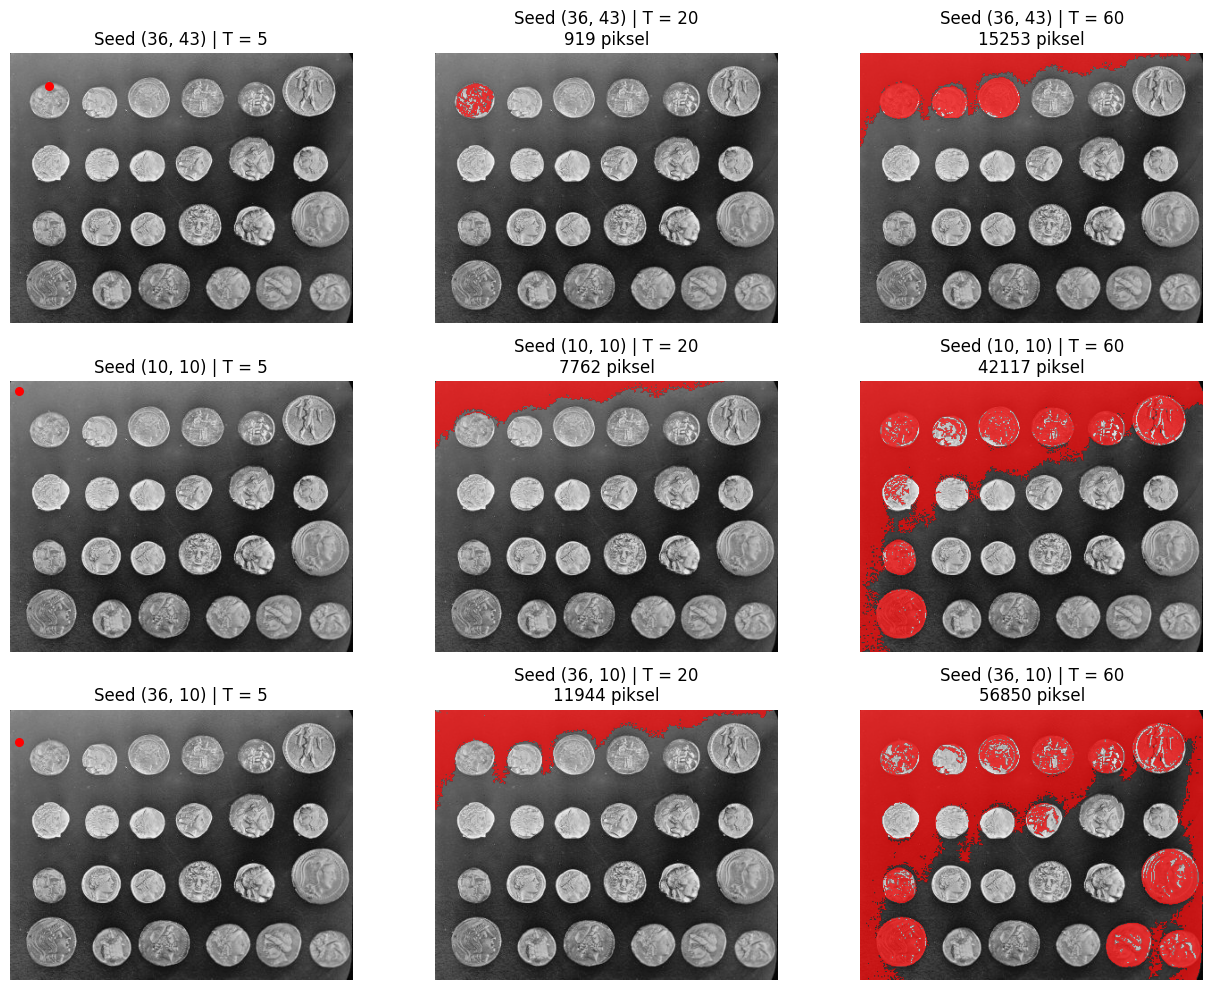

In [14]:

import numpy as np
import matplotlib.pyplot as plt
from collections import deque
from skimage import data

# Memuat citra coins grayscale
img = data.coins()

# Seed: satu di dalam koin, satu di latar, dan satu di tepi koin
seeds = [
    (36, 43),   # Di dalam koin
    (10, 10),   # Di latar
    (36, 10)    # Di tepi koin
]

# Nilai toleransi
tolerances = [5, 20, 60]


def region_growing(gray, seed, tolerance):
    height, width = gray.shape
    seed_value = int(gray[seed])
    region = np.zeros((height, width), dtype=bool)
    visited = np.zeros((height, width), dtype=bool)

    queue = deque([seed])
    visited[seed] = True

    while queue:
        row, col = queue.popleft()
        value = int(gray[row, col])

        if abs(value - seed_value) <= tolerance:
            region[row, col] = True

            # 4-konektivitas: atas, bawah, kiri, kanan
            for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                nr, nc = row + dr, col + dc

                if (
                    0 <= nr < height
                    and 0 <= nc < width
                    and not visited[nr, nc]
                ):
                    visited[nr, nc] = True
                    queue.append((nr, nc))

    return region


# Menampilkan grid 3 x 3
fig, axes = plt.subplots(3, 3, figsize=(13, 10))

for i, seed in enumerate(seeds):
    for j, tolerance in enumerate(tolerances):
        ax = axes[i, j]

        if j == 0:
            ax.imshow(img, cmap='gray')
            ax.scatter(seed[1], seed[0], c='red', s=30)
            ax.set_title(f'Seed {seed} | T = {tolerance}')
        else:
            region = region_growing(img, seed, tolerance)
            ax.imshow(img, cmap='gray')
            ax.imshow(
                np.ma.masked_where(~region, region),
                cmap='autumn',
                alpha=0.7
            )
            ax.set_title(
                f'Seed {seed} | T = {tolerance}\n'
                f'{np.sum(region)} piksel'
            )

        ax.axis('off')

plt.tight_layout()
plt.show()


# No 5

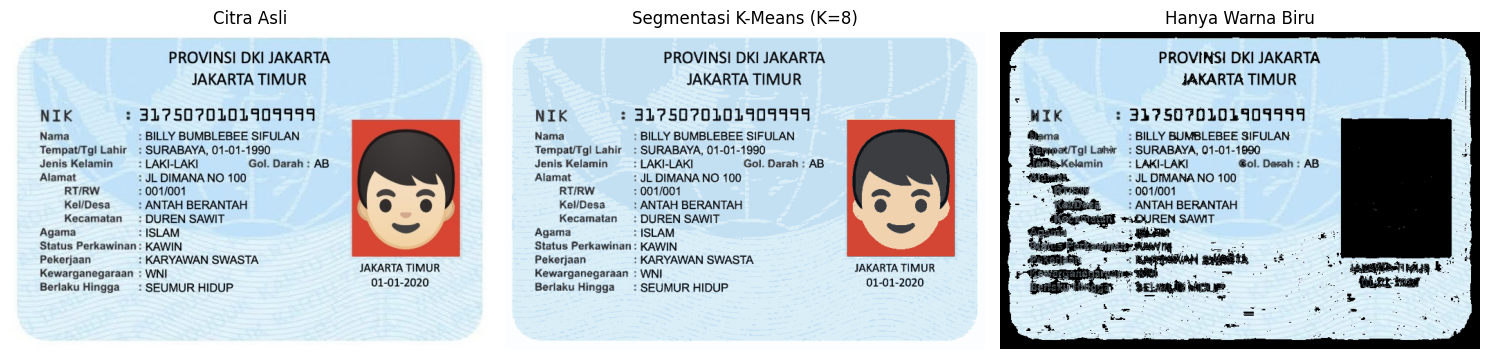

In [15]:

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Membaca gambar
filename = ('/content/drive/MyDrive/Semester 5/PCVK/image/ktpEx.jpeg');
img = cv.imread(filename)

if img is None:
    print("Gambar tidak ditemukan. Periksa lokasi file.")
else:
    # Mengubah warna BGR menjadi RGB untuk ditampilkan
    img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

    # Mengubah citra BGR menjadi HSV
    hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)

    # Segmentasi warna biru menggunakan rentang HSV
    kelompok_biru = np.where(
        (hsv[:, :, 0] >= 85) &
        (hsv[:, :, 0] <= 130) &
        (hsv[:, :, 1] >= 25) &
        (hsv[:, :, 2] >= 40),
        255,
        0
    ).astype(np.uint8)

    # Menerapkan mask untuk menampilkan hanya warna biru
    hanya_biru = cv.bitwise_and(
        img_rgb,
        img_rgb,
        mask=kelompok_biru
    )

    # Segmentasi warna menggunakan K-Means
    pixel_values = img_rgb.reshape((-1, 3)).astype(np.float32)

    criteria = (
        cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER,
        100,
        0.2
    )

    K = 8
    _, labels, centers = cv.kmeans(
        pixel_values,
        K,
        None,
        criteria,
        10,
        cv.KMEANS_RANDOM_CENTERS
    )

    centers = np.uint8(centers)
    segmented = centers[labels.flatten()]
    segmented = segmented.reshape(img_rgb.shape)

    # Menampilkan hasil
    titles = [
        'Citra Asli',
        'Segmentasi K-Means (K=8)',
        'Hanya Warna Biru'
    ]

    images = [img_rgb, segmented, hanya_biru]

    plt.figure(figsize=(15, 6))

    for i in range(3):
        plt.subplot(1, 3, i + 1)
        plt.imshow(images[i])
        plt.title(titles[i])
        plt.axis('off')

    plt.tight_layout()
    plt.show()


# Tugas Kelompok

# No 1

In [16]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


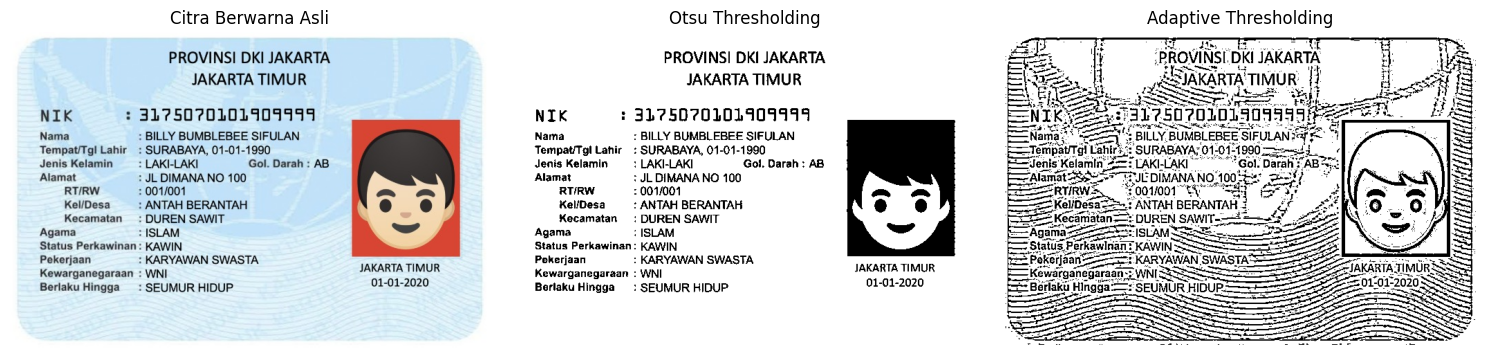

In [17]:

import cv2 as cv
import matplotlib.pyplot as plt

# Membaca citra KTP berwarna
filename = '/content/drive/MyDrive/Semester 5/PCVK/image/ktpEx.jpeg'
img = cv.imread(filename)

if img is None:
    print("Gambar KTP tidak ditemukan. Periksa lokasi file.")
else:
    # Mengubah citra berwarna menjadi grayscale
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # Otsu Thresholding
    _, otsu = cv.threshold(
        gray, 0, 255,
        cv.THRESH_BINARY + cv.THRESH_OTSU
    )

    # Adaptive Thresholding
    adaptive = cv.adaptiveThreshold(
        gray,
        255,
        cv.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv.THRESH_BINARY,
        11,
        2
    )

    # Mengubah BGR menjadi RGB untuk ditampilkan
    img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

    # Menampilkan perbandingan dengan ukuran sama
    plt.figure(figsize=(15, 6))

    plt.subplot(1, 3, 1)
    plt.imshow(img_rgb)
    plt.title('Citra Berwarna Asli')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(otsu, cmap='gray')
    plt.title('Otsu Thresholding')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(adaptive, cmap='gray')
    plt.title('Adaptive Thresholding')
    plt.axis('off')

    plt.tight_layout()
    plt.show()


# No 2

In [18]:
import pytesseract

# Konfigurasi OCR yang sama untuk semua citra
config = '--psm 6 -l ind'

# Membaca teks dari citra berwarna asli
teks_asli = pytesseract.image_to_string(
    img,
    config=config
)

# Membaca teks dari hasil Otsu Thresholding
teks_otsu = pytesseract.image_to_string(
    otsu,
    config=config
)

# Membaca teks dari hasil Adaptive Thresholding
teks_adaptive = pytesseract.image_to_string(
    adaptive,
    config=config
)

# Menampilkan hasil pembacaan teks
print("===== CITRA BERWARNA ASLI =====")
print(teks_asli)

print("\n===== HASIL OTSU THRESHOLDING =====")
print(teks_otsu)

print("\n===== HASIL ADAPTIVE THRESHOLDING =====")
print(teks_adaptive)

===== CITRA BERWARNA ASLI =====
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 31?5070101401911
Nama : BILLY BUMBLEBEE SIFULAN
Tempat#Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW : 001/001

KellDesa — : ANTAH BERANTAH N 4

Kecamatan  : DUREN SAWIT
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR,
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020


===== HASIL OTSU THRESHOLDING =====
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 3)?5D20101401114
Nama : BILLY BUMBLEBEE SIFULAN
TempatiTgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin —: LAKI-LAKI Got, Darah : AB
Alamat ? JL DIMANA NO 100

RTIRW 1 001/001

KellDesa — : ANTAH BERANTAH

Kecamatan: DUREN SAWIT
Agama : ISLAM
Status Perkawinan: KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020


===== HASIL ADAPTIVE THRESHOLDING =====
AE: - Hn INN Anna t 5-3
- PROVINSI DKI JAKARTA F Is


# No 3

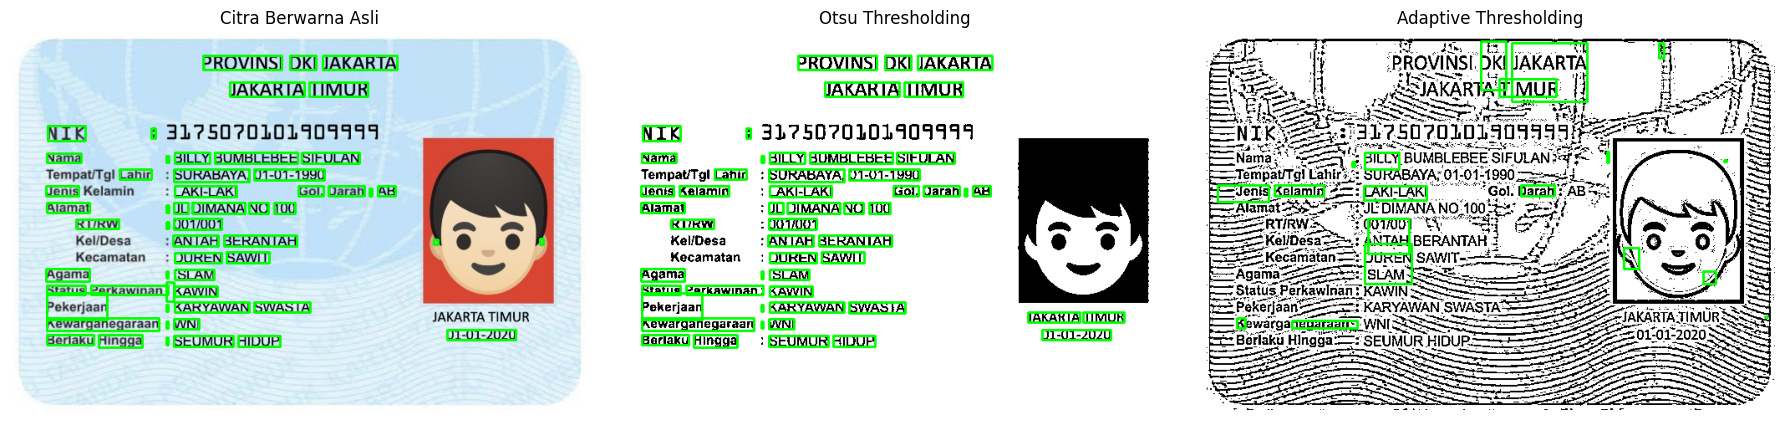

In [19]:

import cv2 as cv
import pytesseract
import matplotlib.pyplot as plt

# Konfigurasi OCR yang sama untuk semua citra
config = '--psm 6 -l ind'
confidence_min = 60

# Tiga citra yang dibandingkan
images = [
    ('Citra Berwarna Asli', img),
    ('Otsu Thresholding', otsu),
    ('Adaptive Thresholding', adaptive)
]

plt.figure(figsize=(18, 7))

for i, (title, image) in enumerate(images):
    # Mengambil data hasil OCR
    data = pytesseract.image_to_data(
        image,
        config=config,
        output_type=pytesseract.Output.DICT
    )

    # Menyiapkan citra untuk menggambar kotak
    if len(image.shape) == 2:
        result = cv.cvtColor(image, cv.COLOR_GRAY2RGB)
    else:
        result = cv.cvtColor(image, cv.COLOR_BGR2RGB)

    # Menggambar kotak pada teks dengan confidence > 60
    for j in range(len(data['text'])):
        text = data['text'][j].strip()

        try:
            confidence = float(data['conf'][j])
        except (ValueError, TypeError):
            continue

        if text and confidence > confidence_min:
            x = data['left'][j]
            y = data['top'][j]
            w = data['width'][j]
            h = data['height'][j]

            cv.rectangle(
                result,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

    # Menampilkan hasil
    plt.subplot(1, 3, i + 1)
    plt.imshow(result)
    plt.title(title)
    plt.axis('off')

plt.tight_layout()
plt.show()


# No 4


| No. | Teks Sebenarnya | OCR Citra Berwarna | OCR Otsu | OCR Adaptive |
|---|---|---|---|---|
| 1 | PROVINSI DKI JAKARTA | PROVINSI DKI JAKARTA | PROVINSI DKI JAKARTA | PROVINSI DKI JAKARTA |
| 2 | JAKARTA TIMUR | JAKARTA TIMUR | JAKARTA TIMUR | JAKARTA TIMUR |
| 3 | NIK | NIK | NIK | NIK |
| 4 | Nama | Nama | Nama | Nama |
| 5 | BILLY BUMBLEBEE SIFULAN | BILLY BUMBLEBEE SIFULAN | BILLY BUMBLEBEE SIFULAN | BILLY BUMBLEBEE SIFULAN |
| 6 | SURABAYA | SURABAYA | SURABAYA | SURABAYA |
| 7 | 01-01-1990 | 01-01-1990 | 01-01-1990 | 01011900 |
| 8 | LAKI-LAKI | LAKI-LAKI | LAKI-LAKI | LAKI-LAKI |
| 9 | DUREN SAWIT | DUREN SAWIT | DUREN SAWIT | DUREN SAM |
| 10 | SEUMUR HIDUP | SEUMUR HIDUP | SEUMUR HIDUP | SEUMUR HIDUP |

# No 5

In [20]:

import pandas as pd
import pytesseract
from IPython.display import display

# 10 teks acuan
acuan = [
    "PROVINSI DKI JAKARTA",
    "JAKARTA TIMUR",
    "NIK",
    "Nama",
    "BILLY BUMBLEBEE SIFULAN",
    "SURABAYA",
    "01-01-1990",
    "LAKI-LAKI",
    "DUREN SAWIT",
    "SEUMUR HIDUP"
]

# Hasil OCR berdasarkan output yang diperoleh sebelumnya
ocr_berwarna = [
    "PROVINSI DKI JAKARTA",
    "JAKARTA TIMUR",
    "NIK",
    "Nama",
    "BILLY BUMBLEBEE SIFULAN",
    "SURABAYA",
    "01-01-1990",
    "LAKI-LAKI",
    "DUREN SAWIT",
    "SEUMUR HIDUP"
]

ocr_otsu = [
    "PROVINSI DKI JAKARTA",
    "JAKARTA TIMUR",
    "NIK",
    "Nama",
    "BILLY BUMBLEBEE SIFULAN",
    "SURABAYA",
    "01-01-1990",
    "LAKI-LAKI",
    "DUREN SAWIT",
    "SEUMUR HIDUP"
]

ocr_adaptive = [
    "PROVINSI DKI JAKARTA",
    "JAKARTA TIMUR",
    "NIK",
    "Nama",
    "BILLY BUMBLEBEE SIFULAN",
    "SURABAYA",
    "01011900",
    "LAKI-LAKI",
    "DUREN SAM",
    "SEUMUR HIDUP"
]

# Menghitung kecocokan tanpa membedakan huruf besar/kecil
def hitung_cocok(hasil, acuan):
    return sum(
        1 for a, h in zip(acuan, hasil)
        if a.strip().casefold() == h.strip().casefold()
    )

# Menghitung rata-rata confidence dari image_to_data
def rata_confidence(image):
    data = pytesseract.image_to_data(
        image,
        config='--psm 6 -l ind',
        output_type=pytesseract.Output.DICT
    )

    confidence = [
        float(c)
        for text, c in zip(data['text'], data['conf'])
        if text.strip() and float(c) >= 0
    ]

    return round(sum(confidence) / len(confidence), 2) if confidence else 0

# Citra yang digunakan
citra_ocr = [
    ("Berwarna asli", ocr_berwarna, img),
    ("Segmentasi Otsu", ocr_otsu, otsu),
    ("Segmentasi Adaptive", ocr_adaptive, adaptive)
]

# Membuat ringkasan
ringkasan = []

for nama, hasil, gambar in citra_ocr:
    jumlah_cocok = hitung_cocok(hasil, acuan)
    persentase = jumlah_cocok / len(acuan) * 100
    confidence = rata_confidence(gambar)

    ringkasan.append({
        "Citra masukan OCR": nama,
        "Item terbaca tepat": f"{jumlah_cocok}/10",
        "Kecocokan (%)": f"{persentase:.2f}%",
        "Rata-rata confidence": confidence
    })

df_ringkasan = pd.DataFrame(ringkasan)
display(df_ringkasan)


,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,10/10,100.00%,80.85
1,Segmentasi Otsu,10/10,100.00%,78.95
2,Segmentasi Adaptive,8/10,80.00%,29.44


# ==Pertanyaan Analisis==

# 1. Citra masukan mana yang menghasilkan pembacaan paling tepat?
Citra berwarna asli menghasilkan pembacaan yang paling tepat, diikuti oleh citra hasil Otsu. Berdasarkan tabel perbandingan sebelumnya, citra berwarna dan Otsu memiliki kecocokan lebih tinggi daripada Adaptive Thresholding.

# 2. Sebutkan minimal dua kesalahan pembacaan.
1. Tanggal lahir: Teks sebenarnya 01-01-1990, tetapi OCR Adaptive membaca 01011900.
2. Kecamatan: Teks sebenarnya DUREN SAWIT, tetapi OCR Adaptive membaca DUREN SAM.
Kesalahan tersebut menunjukkan bahwa perubahan bentuk karakter akibat thresholding dapat menyebabkan huruf atau angka dikenali secara keliru.

# 3. Apakah segmentasi selalu meningkatkan ketepatan OCR?
Tidak. Pada percobaan ini, Otsu menghasilkan pembacaan yang cukup baik, tetapi Adaptive Thresholding justru menghasilkan lebih banyak kesalahan. Segmentasi dapat meningkatkan kontras teks, tetapi juga dapat menghilangkan detail karakter atau membuat pola latar belakang terbaca sebagai tulisan.

# 4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?
Warna dan pola latar belakang memengaruhi kontras antara tulisan dan area di sekitarnya. Pada KTP, latar belakang berwarna biru memiliki pola yang cukup rumit. Adaptive Thresholding dapat membuat pola tersebut semakin menonjol sehingga OCR salah mengenali pola sebagai karakter. Sementara itu, citra berwarna asli masih mempertahankan informasi warna dan detail tulisan.

# 5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?
Belum tentu. Nilai confidence menunjukkan tingkat keyakinan Tesseract terhadap hasil pengenalannya, bukan jaminan bahwa teks tersebut benar. Suatu metode dapat memiliki confidence tinggi tetapi tetap salah membaca angka atau huruf. Karena itu, nilai confidence harus dibandingkan dengan persentase kecocokan terhadap teks sebenarnya.